In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

df = pd.read_csv("../data/train.csv")
print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print(df.isna().sum().sort_values(ascending=False))
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64
Cabin          77.1
Age            19.9
Embarked        0.2
PassengerId     0.0
Name            0.0
Pclass          0.0
Survived        0.0
Sex             0.0
Parch           0.0
SibSp           0.0
Fare            0.0
Ticket          0.0
dtype: float64


In [8]:
print("Cabin уникальных: ", df["Cabin"].nunique(), "| заполнено:", df["Cabin"].notna().sum())

Cabin уникальных:  147 | заполнено: 204


Много пропусков в Cabin - в целом неважный признак, нужно дропать.

In [6]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
print(df[num_cols].describe().T)

          count       mean        std   min      25%      50%   75%       max
Survived  891.0   0.383838   0.486592  0.00   0.0000   0.0000   1.0    1.0000
Pclass    891.0   2.308642   0.836071  1.00   2.0000   3.0000   3.0    3.0000
Age       714.0  29.699118  14.526497  0.42  20.1250  28.0000  38.0   80.0000
SibSp     891.0   0.523008   1.102743  0.00   0.0000   0.0000   1.0    8.0000
Parch     891.0   0.381594   0.806057  0.00   0.0000   0.0000   0.0    6.0000
Fare      891.0  32.204208  49.693429  0.00   7.9104  14.4542  31.0  512.3292


In [7]:
for col in ["Survived", "Pclass", "Sex", "Embarked", "SibSp", "Parch"]:
    print(f"\n=== {col} ===")
    vc = df[col].value_counts(dropna=False)
    print(pd.DataFrame({"count": vc, "pct": (vc / len(df) * 100).round(1)}))


=== Survived ===
          count   pct
Survived             
0           549  61.6
1           342  38.4

=== Pclass ===
        count   pct
Pclass             
3         491  55.1
1         216  24.2
2         184  20.7

=== Sex ===
        count   pct
Sex                
male      577  64.8
female    314  35.2

=== Embarked ===
          count   pct
Embarked             
S           644  72.3
C           168  18.9
Q            77   8.6
NaN           2   0.2

=== SibSp ===
       count   pct
SibSp             
0        608  68.2
1        209  23.5
2         28   3.1
4         18   2.0
3         16   1.8
8          7   0.8
5          5   0.6

=== Parch ===
       count   pct
Parch             
0        678  76.1
1        118  13.2
2         80   9.0
5          5   0.6
3          5   0.6
4          4   0.4
6          1   0.1


In [10]:
print(df["Survived"].value_counts(normalize=True).round(3))
print("\nВыживаемость по полу:\n",      df.groupby("Sex")["Survived"].agg(["mean","count"]).round(3))
print("\nВыживаемость по классу:\n",    df.groupby("Pclass")["Survived"].agg(["mean","count"]).round(3))
print("\nВыживаемость по Embarked:\n",  df.groupby("Embarked")["Survived"].agg(["mean","count"]).round(3))

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

Выживаемость по полу:
          mean  count
Sex                 
female  0.742    314
male    0.189    577

Выживаемость по классу:
          mean  count
Pclass              
1       0.630    216
2       0.473    184
3       0.242    491

Выживаемость по Embarked:
            mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.337    644


In [11]:
print("\nКросс-таблица Pclass × Sex (доли выживших):")
print(pd.crosstab(df["Pclass"], df["Sex"], values=df["Survived"], aggfunc="mean").round(3))


Кросс-таблица Pclass × Sex (доли выживших):
Sex     female   male
Pclass               
1        0.968  0.369
2        0.921  0.157
3        0.500  0.135


Во всех классах женщины выживают чаще мужчин. Чем выше класс - тем больше выживаемость

In [ ]:
print(df.groupby("Sex")["Age"].describe().round(1))
print(df.groupby("Pclass")["Fare"].describe().round(1))
print(df.groupby("Survived")[["Age","Fare","SibSp","Parch"]].mean().round(1))

        count  mean   std  min   25%   50%   75%   max
Sex                                                   
female  261.0  27.9  14.1  0.8  18.0  27.0  37.0  63.0
male    453.0  30.7  14.7  0.4  21.0  29.0  39.0  80.0
        count  mean   std  min   25%   50%   75%    max
Pclass                                                 
1       216.0  84.2  78.4  0.0  30.9  60.3  93.5  512.3
2       184.0  20.7  13.4  0.0  13.0  14.2  26.0   73.5
3       491.0  13.7  11.8  0.0   7.8   8.0  15.5   69.6
           Age  Fare  SibSp  Parch
Survived                          
0         30.6  22.1    0.6    0.3
1         28.3  48.4    0.5    0.5


          Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
Age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp        -0.04    0.08 -0.31   1.00   0.41  0.16
Parch         0.08    0.02 -0.19   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00


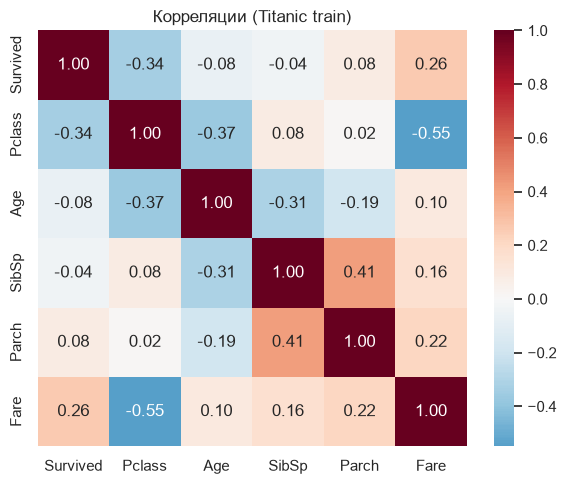

In [ ]:
corr = df[["Survived","Pclass","Age","SibSp","Parch","Fare"]].corr()
print(corr.round(2))

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Корреляции (Titanic train)")
plt.tight_layout(); plt.show()

Хочется дропнуть SibSp или Parch как линейно зависимые, чтобы не захламлять датасет, выбор в сторону признака с меньшей корреляцией с таргетом

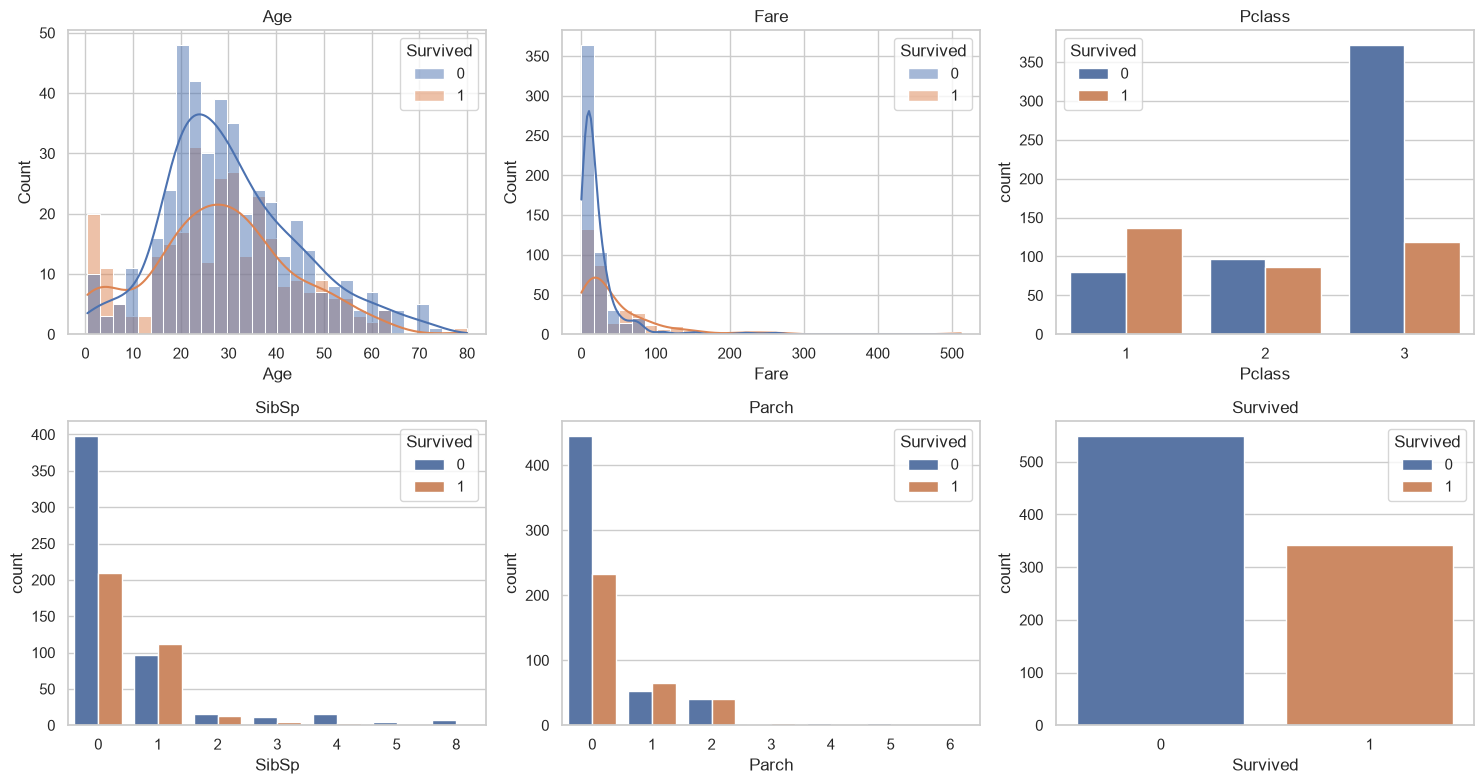

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ["Age", "Fare", "Pclass", "SibSp", "Parch", "Survived"]
for ax, col in zip(axes.ravel(), cols):
    if col in ("Pclass","SibSp","Parch","Survived"):
        sns.countplot(data=df, x=col, hue="Survived", ax=ax)
    else:
        sns.histplot(data=df, x=col, hue="Survived", bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

Почти нормально распределение по возрасту/выживаемости, выбросы только около 0, можно будет дозаполнить Age = mean() 

In [14]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "SibSp"])
df.head()

,Survived,Pclass,Sex,Age,Parch,Fare,Embarked
0,0,3,male,22.0,0,7.2500,S
1,1,1,female,38.0,0,71.2833,C
2,1,3,female,26.0,0,7.9250,S
3,1,1,female,35.0,0,53.1000,S
4,0,3,male,35.0,0,8.0500,S
